# 02 · Workflow model and metrics (Class 7)

**Project KPI:** reduce the late delivery rate.
**Business question:** *Where in the order lifecycle does delay accumulate, and are interventions reaching late orders in time?*

Raw systems are organised by source; this notebook reorganises them around one order's journey. It reads the **silver** table produced by `python run_pipeline.py --run-date 2026-08-29`.

In [1]:
import sys, json, logging, tempfile, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)
logging.basicConfig(level=logging.INFO, format="%(levelname)-7s | %(message)s", force=True)
logging.getLogger("matplotlib").setLevel(logging.WARNING)
log = logging.getLogger("notebook")

from pipeline.config import load_config
cfg = load_config(root=ROOT)
RUN = "2026-08-29"
journey = pd.read_csv(ROOT / f"data/silver/run_date={RUN}/order_journey.csv",
                      parse_dates=["created_at", "promised_eta", "pickup_at", "actual_delivery_at", "assigned_at", "app_delivered_at"])
metrics = json.loads((ROOT / f"data/gold/run_date={RUN}/metrics.json").read_text())
print(journey.shape)

(1600, 55)


## 1 · Start with one order, not an ER diagram

Entities persist (order, customer, restaurant, driver, ticket). Events happen (created, assigned, picked up, delivered, intervention). State is where the order is now. Three real orders:

In [2]:
from pipeline.extract import extract_csv, extract_driver_events
tmp = Path(tempfile.mkdtemp())
events = extract_csv(ROOT / "source_data/files/order_events.csv", "order_events", tmp, log).df
interventions = extract_csv(ROOT / "source_data/files/order_interventions.csv", "interventions", tmp, log).df

m = journey[journey.is_measurable]
examples = {
    "on time": m[(m.is_late == False) & (m.intervention_count == 0)].order_id.iloc[0],
    "late, no intervention": m[(m.is_late == True) & (m.intervention_count == 0) & (m.assigned_to_pickup_min > 30)].order_id.iloc[0],
    "late, intervened": m[(m.is_late == True) & (m.preventive_intervention_count > 0)].order_id.iloc[0],
}

def timeline(oid):
    j = journey.set_index("order_id").loc[oid]
    rows = [("order created", j.created_at), ("driver assigned (dispatch API)", j.assigned_at),
            ("picked up", j.pickup_at), ("PROMISED", j.promised_eta), ("delivered", j.actual_delivery_at)]
    for r in interventions[interventions.order_id == oid].itertuples():
        rows.append((f"intervention: {r.intervention_type} by {r.initiated_by} ({r.reason})",
                     pd.to_datetime(r.intervention_at, format="mixed")))
    t = pd.DataFrame(rows, columns=["event", "time"]).sort_values("time")
    t["min_from_created"] = ((t.time - j.created_at).dt.total_seconds() / 60).round(1)
    return t

for label, oid in examples.items():
    j = journey.set_index("order_id").loc[oid]
    print(f"\n=== {oid} · {label} · delay {j.delay_min:+.1f} min · assigned->pickup {j.assigned_to_pickup_min:.1f} min ===")
    print(timeline(oid).to_string(index=False))

INFO    | CSV order_events rows=4955 complete=True


INFO    | CSV interventions rows=430 complete=True



=== O00003 · on time · delay -4.4 min · assigned->pickup 22.8 min ===
                         event                time  min_from_created
                 order created 2026-08-01 19:35:00               0.0
driver assigned (dispatch API) 2026-08-01 19:35:00               0.0
                     picked up 2026-08-01 19:57:50              22.8
                     delivered 2026-08-01 20:13:28              38.5
                      PROMISED 2026-08-01 20:17:52              42.9

=== O00005 · late, no intervention · delay +21.0 min · assigned->pickup 41.7 min ===
                         event                time  min_from_created
                 order created 2026-08-06 20:35:00               0.0
driver assigned (dispatch API) 2026-08-06 20:36:55               1.9
                     picked up 2026-08-06 21:18:38              43.6
                      PROMISED 2026-08-06 21:54:48              79.8
                     delivered 2026-08-06 22:15:49             100.8

=== O00001 · l

## 2 · The relational / event model

See [`docs/data_model.md`](../docs/data_model.md) for the diagram. The rule that keeps it trustworthy is **grain**: every 1:N source is aggregated to `order_id` *before* the join. Here is why:

In [3]:
orders_only = journey[["order_id"]]
naive = orders_only.merge(events, on="order_id", how="left").merge(interventions, on="order_id", how="left")
print(f"orders: {len(orders_only):,} | naive join of events + interventions: {len(naive):,} rows "
      f"({len(naive)/len(orders_only):.1f}x fan-out) | order_journey: {len(journey):,} rows, {journey.order_id.nunique():,} unique")

orders: 1,600 | naive join of events + interventions: 4,955 rows (3.1x fan-out) | order_journey: 1,600 rows, 1,600 unique


## 3 · The five metrics

In [4]:
rows = []
for key, v in metrics["metrics"].items():
    headline = {k: val for k, val in v.items() if k not in ("formula", "grain", "role", "caution", "stages", "definition")}
    rows.append({"metric": key, "role": v["role"], "values": headline, "grain": v["grain"]})
pd.DataFrame(rows)

,metric,role,values,grain
0,M1_late_delivery_rate,Project KPI,"{'value_pct': 56.4, 'numerator_late_orders': 843, 'denominator_measurable_deliveries':...",order
1,M2_late_severity,How bad is late? (Support Lead's >10 min view),"{'median_delay_of_late_orders_min': 8.0, 'p90_delay_of_late_orders_min': 22.3, 'late_o...",order
2,M3_stage_delay_gap,Where in the workflow delay accumulates,{'largest_gap_stage': 'assigned_to_pickup_min'},order x workflow stage
3,M4_pickup_wait_breach,Leading indicator Ops can act on before the ETA is missed,"{'threshold_min': 25, 'breach_rate_pct': 41.2, 'late_rate_when_breached_pct': 94.4, 'l...",order
4,M5_intervention_coverage,Are interventions reaching late orders in time?,"{'late_orders_with_any_intervention_pct': 27.0, 'late_orders_with_preventive_intervent...",order (interventions aggregated to order)


### M3 · Where does delay accumulate?

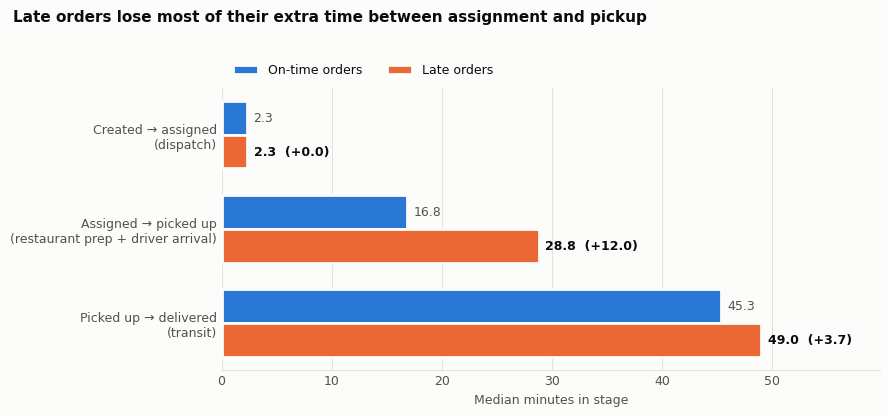

In [5]:
import matplotlib.pyplot as plt

# Reference palette (dataviz skill): categorical slot 1 = blue, slot 2 = orange; light surface + text tokens.
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
ON_TIME, LATE = "#2a78d6", "#eb6834"

stages = metrics["metrics"]["M3_stage_delay_gap"]["stages"]
labels = ["Created → assigned\n(dispatch)", "Assigned → picked up\n(restaurant prep + driver arrival)", "Picked up → delivered\n(transit)"]
on = [s["median_on_time_min"] for s in stages.values()]
lt = [s["median_late_min"] for s in stages.values()]

fig, ax = plt.subplots(figsize=(9, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
y = range(len(labels))
h = 0.36
ax.barh([i - h / 2 for i in y], on, height=h, color=ON_TIME, edgecolor=SURFACE, linewidth=2, label="On-time orders")
ax.barh([i + h / 2 for i in y], lt, height=h, color=LATE, edgecolor=SURFACE, linewidth=2, label="Late orders")
for i, (a, b) in enumerate(zip(on, lt)):
    ax.text(a + 0.6, i - h / 2, f"{a:.1f}", va="center", fontsize=9, color=TEXT_2)
    ax.text(b + 0.6, i + h / 2, f"{b:.1f}  (+{b - a:.1f})", va="center", fontsize=9, color=TEXT, fontweight="bold")
ax.set_yticks(list(y), labels, fontsize=9, color=TEXT)
ax.invert_yaxis()
ax.set_xlabel("Median minutes in stage", color=TEXT_2, fontsize=9)
ax.tick_params(colors=TEXT_2, labelsize=9, length=0)
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
for side in ("top", "right", "left"): ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.set_xlim(0, max(lt + on) * 1.22)
ax.legend(frameon=False, fontsize=9, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, labelcolor=TEXT)
fig.suptitle("Late orders lose most of their extra time between assignment and pickup",
             x=0.02, ha="left", fontsize=11, color=TEXT, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(ROOT / "docs/stage_delay_gap.png", dpi=160, facecolor=SURFACE)
plt.show()

### Is traffic the real cause? (the client's hypothesis)

In [6]:
by_traffic = m.groupby("traffic_bucket").agg(
    orders=("order_id", "size"),
    late_rate_pct=("is_late", lambda s: round(100 * s.mean(), 1)),
    median_assigned_to_pickup=("assigned_to_pickup_min", "median"),
    median_transit=("pickup_to_delivered_min", "median"),
).reindex(["low", "medium", "high", "severe"]).round(1)
by_traffic

,orders,late_rate_pct,median_assigned_to_pickup,median_transit
traffic_bucket,,,,
low,360,49.4,23.2,43.5
medium,588,51.4,22.9,46.8
high,424,66.5,23.7,53.1
severe,123,65.9,21.8,61.9


**Reading:** traffic *is* associated with lateness (high/severe ≈ 66% late vs ≈ 49% low), and it shows up where you'd expect: **transit** grows from ~44 to ~62 min. But **assigned → pickup is flat across traffic buckets (~22–24 min)**, even though that stage has the largest late-vs-on-time gap (M3, +12 min). So the biggest source of delay is *not* explained by traffic. The client's "traffic is the problem" story is only partly true.

What sits inside assigned → pickup? Restaurant prep time **and** the driver's trip to the restaurant. Because the stage doesn't move with traffic, the restaurant side is the more likely cause. We still can't prove it: no source has a **"driver arrived at restaurant" event**. This is our most important *Unknown*, and the first instrumentation recommendation.

### M4 · Pickup-wait breach as a leading indicator (no ML needed)

In [7]:
b = m[m.pickup_wait_breach.notna()]
pd.crosstab(b.pickup_wait_breach.map({True: "assigned→pickup > 25 min", False: "≤ 25 min"}),
            b.is_late.map({True: "late", False: "on time"}), margins=True)

is_late,late,on time,All
pickup_wait_breach,,,
assigned→pickup > 25 min,576,34,610
≤ 25 min,267,604,871
All,843,638,1481


### M5 · Do interventions reach late orders in time?

In [8]:
iv = interventions.merge(journey[["order_id", "actual_delivery_at", "is_late"]], on="order_id")
iv["intervention_at"] = pd.to_datetime(iv.intervention_at, format="mixed")
iv["timing"] = (iv.intervention_at < iv.actual_delivery_at).map({True: "before delivery", False: "after delivery"})
iv.loc[iv.actual_delivery_at.isna(), "timing"] = "order not delivered / unknown"
pd.crosstab(iv.intervention_type, iv.timing, margins=True)

timing,after delivery,before delivery,order not delivered / unknown,All
intervention_type,,,,
CUSTOMER_CREDIT,45,18,1,64
DRIVER_REASSIGNMENT,0,147,8,155
PRIORITY_DISPATCH,0,86,9,95
RESTAURANT_CONTACT,0,108,8,116
All,45,359,26,430


**Reading:** 73% of late orders get **no intervention at all**, and most `CUSTOMER_CREDIT` actions happen after delivery (recovery, not prevention). Late rate is 56.8% for orders with a preventive intervention vs 56.4% without, but interventions are *triggered* by late risk, so this is **association, not effect**. Measuring effect needs a controlled trial (see limitations).

## 4 · Sensitivity of the KPI to the definition

In [9]:
pd.read_csv(ROOT / f"data/gold/run_date={RUN}/late_definition_sensitivity.csv")[["definition", "late_orders", "denominator", "late_rate_pct", "canonical"]]

,definition,late_orders,denominator,late_rate_pct,canonical
0,fde_agreed,843,1495,56.4,True
1,vp_operations,843,1532,55.0,False
2,support_lead,349,1495,23.3,False
3,finance_naive_all_orders,843,1600,52.7,False
4,data_team_dashboard,843,1495,56.4,False
5,sensitivity_driver_app_backfill,867,1532,56.6,False


## 5 · What this supports

**Decision:** do **not** build the AI delay predictor yet. The delay concentrates in one workflow stage that is **not instrumented** (no driver-arrival event), and the 37 missing delivery timestamps plus conflicting intervention logs mean a model would learn from gaps. Instead:
1. Add a `driver_arrived_at_restaurant` event (separates prep from driver travel).
2. Use M4 (assigned → pickup > 25 min) as a rule-based trigger for `RESTAURANT_CONTACT` / `PRIORITY_DISPATCH` *before* the ETA is missed.
3. Track M1–M5 daily from this pipeline; revisit ML once M4 interventions have been run as a controlled trial.